# Taxonomia de produtos do Google: exploratory analysis

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
cat = pd.read_parquet(root / 'data' / 'categorias.parquet')
hier = pd.read_parquet(root / 'data' / 'hierarquia.parquet')
print(cat.shape, hier.shape)

(5595, 14) (22907, 4)


## Categories per top level

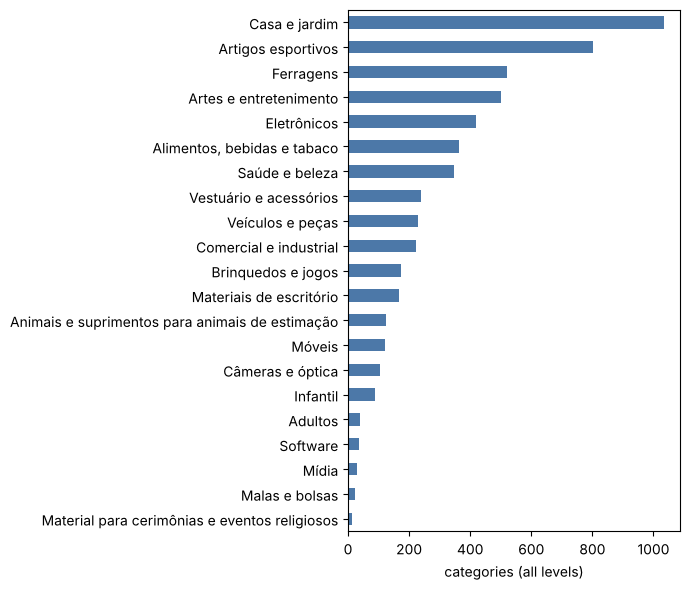

In [2]:
ax = cat.groupby('top_level_pt').size().sort_values().plot.barh(figsize=(7, 6), color='#4C78A8')
ax.set_xlabel('categories (all levels)')
ax.set_ylabel('')
plt.tight_layout()

## Depth of the tree

In [3]:
cat.groupby('level').agg(categories=('google_id', 'size'), leaves=('is_leaf', 'sum'))

,categories,leaves
level,,
1,21,0
2,192,52
3,1349,1015
4,2203,1928
5,1385,1297
6,397,379
7,48,48


## Widest nodes (most direct children)

In [4]:
cat.nlargest(10, 'child_count')[['google_id', 'path_pt', 'child_count']]

,google_id,path_pt,child_count
4055,1167,Ferragens > Ferramentas,79
2686,668,Casa e jardim > Produtos de cozinha e aparelho...,77
2186,696,Casa e jardim > Decoração,75
170,5793,"Alimentos, bebidas e tabaco > Alimentos > Frut...",58
2872,730,Casa e jardim > Produtos de cozinha e aparelho...,52
404,2,Animais e suprimentos para animais de estimaçã...,46
111,5795,"Alimentos, bebidas e tabaco > Alimentos > Frut...",43
4169,1305,Ferragens > Ferramentas > Sensores e ferrament...,38
254,2660,"Alimentos, bebidas e tabaco > Alimentos > Ingr...",36
2609,2901,Casa e jardim > Produtos de cozinha e aparelho...,33


## Descendants per top level, from the closure table

In [5]:
desc = hier[hier['distance'] > 0].groupby('ancestor_id').size().rename('descendants')
cat[cat['level'] == 1].set_index('google_id').join(desc)[['name_pt', 'name_en', 'descendants']].sort_values('descendants', ascending=False)

,name_pt,name_en,descendants
google_id,,,
536,Casa e jardim,Home & Garden,1034
988,Artigos esportivos,Sporting Goods,800
632,Ferragens,Hardware,521
8,Artes e entretenimento,Arts & Entertainment,499
222,Eletrônicos,Electronics,417
412,"Alimentos, bebidas e tabaco","Food, Beverages & Tobacco",363
469,Saúde e beleza,Health & Beauty,345
166,Vestuário e acessórios,Apparel & Accessories,239
888,Veículos e peças,Vehicles & Parts,229


## Deepest paths (level 7)

In [6]:
for path in cat.loc[cat['level'] == 7, 'path_pt'].head(5):
    print(path)

Artes e entretenimento > Hobbies e artes > Acessórios para instrumentos musicais e orquestras > Acessórios para instrumentos de sopro de madeira > Acessórios para clarinete > Manutenção e limpeza de clarinete > Escovas de limpeza para clarinete
Artes e entretenimento > Hobbies e artes > Acessórios para instrumentos musicais e orquestras > Acessórios para instrumentos de sopro de madeira > Acessórios para clarinete > Manutenção e limpeza de clarinete > Kits de manutenção para clarinete
Artes e entretenimento > Hobbies e artes > Acessórios para instrumentos musicais e orquestras > Acessórios para instrumentos de sopro de madeira > Acessórios para clarinete > Manutenção e limpeza de clarinete > Protetores de sapatilhas para clarinete
Artes e entretenimento > Hobbies e artes > Acessórios para instrumentos musicais e orquestras > Acessórios para instrumentos de sopro de madeira > Acessórios para clarinete > Peças para clarinete > Barriletes para clarinete
Artes e entretenimento > Hobbies e 

## Bilingual lookup

In [7]:
def find(term):
    mask = cat['name_pt'].str.contains(term, case=False) | cat['name_en'].str.contains(term, case=False)
    return cat.loc[mask, ['google_id', 'name_pt', 'name_en', 'level']]

find('café')

,google_id,name_pt,name_en,level
298,4418,Cremeira para café,Coffee Creamer,4
320,6196,Bolos de café,Coffee Cakes,4
383,1868,Café,Coffee,3
2640,3988,Acessórios para máquina de café e para máquina...,Coffee Maker & Espresso Machine Accessories,4
2641,4786,Acessórios para moedor de café,Coffee Grinder Accessories,5
2642,6888,Aquecedores para decantador de café,Coffee Decanter Warmers,5
2643,4500,Cestas para filtros de café,Coffee Filter Baskets,5
2645,3450,Filtros de café,Coffee Filters,5
2646,3239,Garrafas de café,Coffee Decanters,5
2647,5066,Jarras para café expresso,Frothing Pitchers,5


## The nested tree

In [8]:
tree = json.loads((root / 'data' / 'arvore.json').read_text(encoding='utf-8'))
print(tree['version'], [n['name_pt'] for n in tree['children']][:6])

2021-09-21 ['Adultos', 'Alimentos, bebidas e tabaco', 'Animais e suprimentos para animais de estimação', 'Artes e entretenimento', 'Artigos esportivos', 'Brinquedos e jogos']
